# DELE CA1 Part A

In [113]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import tensorflow as tf
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("C:/Users/Enzo/schEnzo/OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")

# Show the first few rows
print(df.head())

# Shape of dataset
print("Shape:", df.shape)  

# Info summary of dataset (columns, non-null counts, datatypes, memory)
print("\n", df.info())

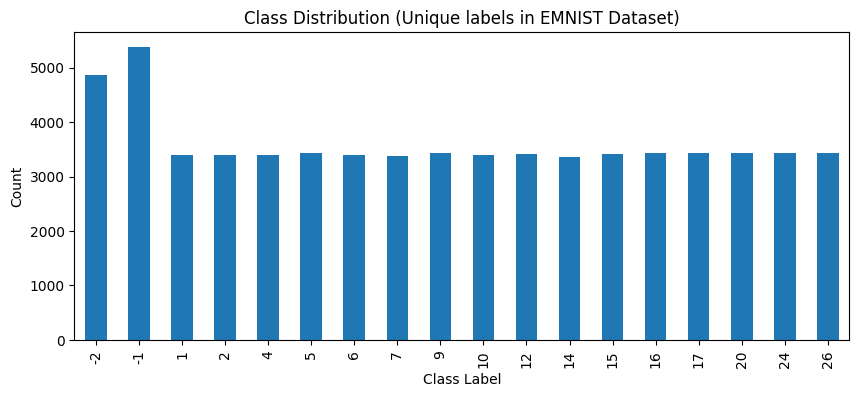

Unique labels in dataset: [-2, -1, 1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]


In [79]:
labels = df.iloc[:, 0]  # First column is label (1 to 26 for A-Z)

plt.figure(figsize=(10, 4))
labels.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution (Unique labels in EMNIST Dataset)")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

print("Unique labels in dataset:", sorted(df.iloc[:, 0].unique()))

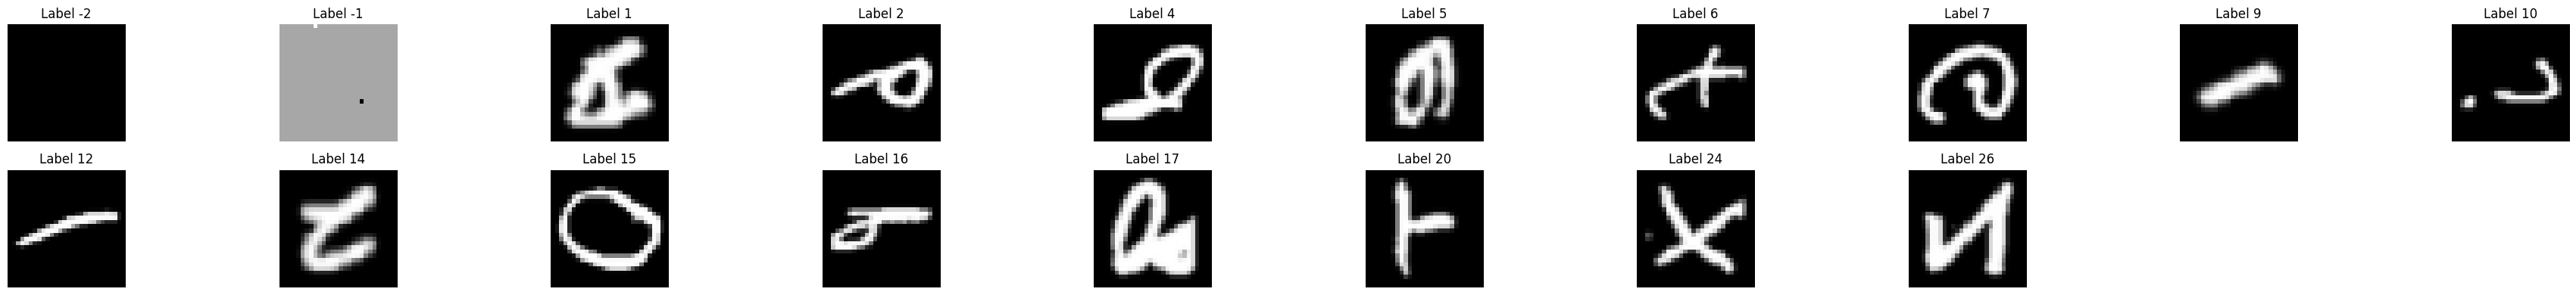

In [42]:
available_labels = sorted(df.iloc[:, 0].unique())

plt.figure(figsize=(len(available_labels) * 2, 4))  # Adjust figure width dynamically
for i, label in enumerate(available_labels):
    img = df[df.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    plt.subplot(2, len(available_labels) // 2 + 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

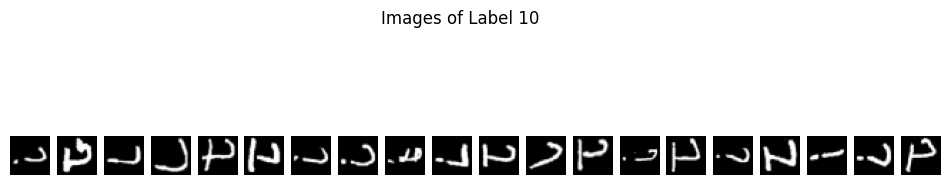

In [95]:
label_to_show = 10

subset = df[df.iloc[:, 0] == label_to_show]

plt.figure(figsize=(12, 3))
for i in range(20):
    img = subset.iloc[i, 1:].values.reshape(28, 28)
    plt.subplot(1, 20, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle(f"Images of Label {label_to_show}")
plt.show()

# -2 -1 9 10 12 are weird, -2 -1 not real, -10 ?????, 9 12 look same

In [107]:
# Your original labels
labels = df.iloc[:, 0].values

# Filter out invalid labels, e.g. negative values (customize as needed)
valid_labels_mask = labels >= 0
labels = labels[valid_labels_mask]
X_filtered = df.iloc[valid_labels_mask, 1:].values.reshape(-1, 28, 28, 1).astype('float32')

In [108]:
# Normalize to [-1, 1] for GANs
X_filtered = (X_filtered - 127.5) / 127.5

# Sanity check
print("Pixel mean:", X_filtered.mean())
print("Pixel std:", X_filtered.std())

Pixel mean: -0.65534747
Pixel std: 0.6626988


In [109]:
# Get unique sorted valid labels
unique_labels = sorted(np.unique(labels))

# Map original labels to zero-based
label_to_index = {label: idx for idx, label in enumerate(unique_labels)}
mapped_labels = np.array([label_to_index[label] for label in labels])

# Check mapping
print("Original labels:", unique_labels)
print("Mapped label range:", mapped_labels.min(), "to", mapped_labels.max())

Original labels: [1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]
Mapped label range: 0 to 15


In [ ]:
BUFFER_SIZE = 10000
BATCH_SIZE = 128

# Split before creating tf.data.Dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_filtered, mapped_labels, test_size=0.2, random_state=42, stratify=mapped_labels
)

# Create tf.data.Dataset objects
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)

Epoch 1/5


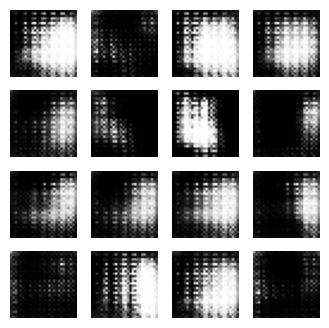

Epoch 2/5


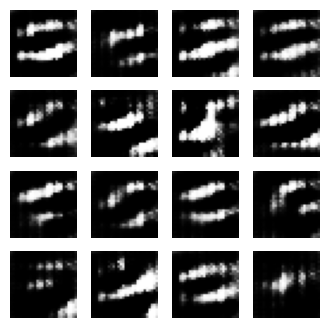

Epoch 3/5


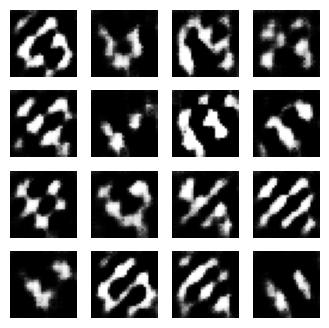

Epoch 4/5


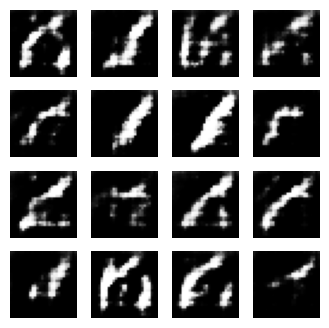

Epoch 5/5


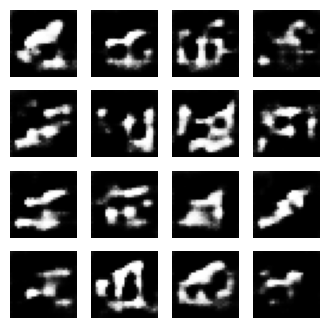

In [ ]:
# # === 2. Generator Model ===
# def make_generator_model():
#     model = tf.keras.Sequential([
#         layers.Dense(7*7*256, use_bias=False, input_shape=(100,)),
#         layers.BatchNormalization(),
#         layers.LeakyReLU(),

#         layers.Reshape((7, 7, 256)),  # 7x7x256

#         layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False),
#         layers.BatchNormalization(),
#         layers.LeakyReLU(),

#         layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
#         layers.BatchNormalization(),
#         layers.LeakyReLU(),

#         layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')
#     ])
#     return model

# # === 3. Discriminator Model ===
# def make_discriminator_model():
#     model = tf.keras.Sequential([
#         layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
#         layers.LeakyReLU(),
#         layers.Dropout(0.3),

#         layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
#         layers.LeakyReLU(),
#         layers.Dropout(0.3),

#         layers.Flatten(),
#         layers.Dense(1)
#     ])
#     return model

# # === 4. Loss & Optimizer ===
# cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# def discriminator_loss(real_output, fake_output):
#     real_loss = cross_entropy(tf.ones_like(real_output), real_output)
#     fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
#     return real_loss + fake_loss

# def generator_loss(fake_output):
#     return cross_entropy(tf.ones_like(fake_output), fake_output)

# generator = make_generator_model()
# discriminator = make_discriminator_model()

# generator_optimizer = tf.keras.optimizers.Adam(1e-4)
# discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

# # === 5. Training Loop ===
# EPOCHS = 5
# noise_dim = 100
# num_examples_to_generate = 16
# seed = tf.random.normal([num_examples_to_generate, noise_dim])

# @tf.function
# def train_step(images):
#     noise = tf.random.normal([BATCH_SIZE, noise_dim])

#     with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
#         generated_images = generator(noise, training=True)

#         real_output = discriminator(images, training=True)
#         fake_output = discriminator(generated_images, training=True)

#         gen_loss = generator_loss(fake_output)
#         disc_loss = discriminator_loss(real_output, fake_output)

#     gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
#     gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

#     generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
#     discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

# def generate_and_save_images(model, epoch, test_input):
#     predictions = model(test_input, training=False)
#     predictions = (predictions + 1) / 2.0  # Rescale to [0, 1]

#     fig = plt.figure(figsize=(4, 4))
#     for i in range(predictions.shape[0]):
#         plt.subplot(4, 4, i+1)
#         plt.imshow(predictions[i, :, :, 0], cmap='gray')
#         plt.axis('off')
#     plt.savefig(f'image_epoch_{epoch}.png')
#     plt.show()

# def train(dataset, epochs):
#     for epoch in range(epochs):
#         print(f"Epoch {epoch+1}/{epochs}")
#         for image_batch in dataset:
#             train_step(image_batch)
#         generate_and_save_images(generator, epoch + 1, seed)

# train(dataset_images_only, EPOCHS)

Epoch 1/10


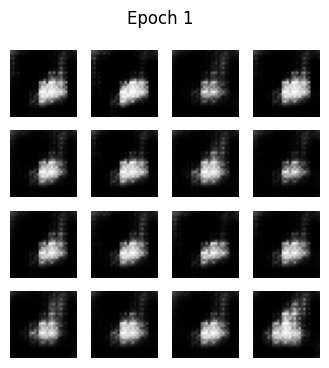

Epoch 2/10


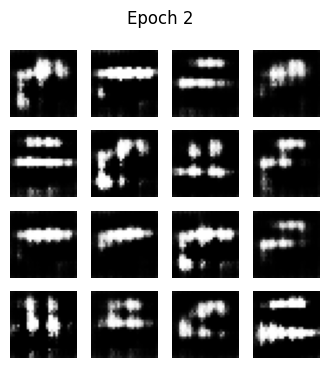

Epoch 3/10


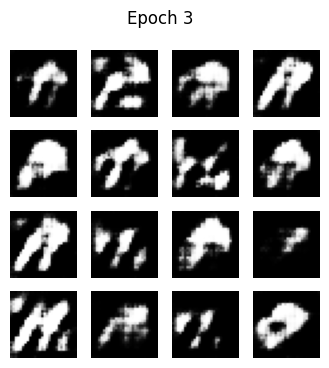

Epoch 4/10


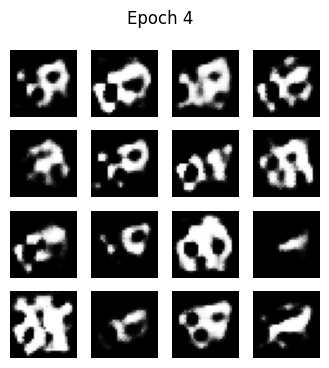

Epoch 5/10


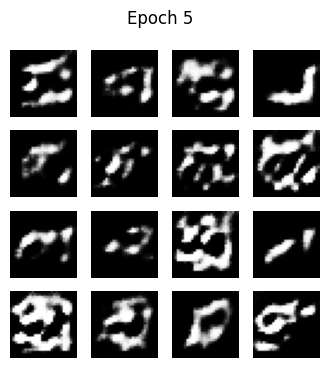

Epoch 6/10


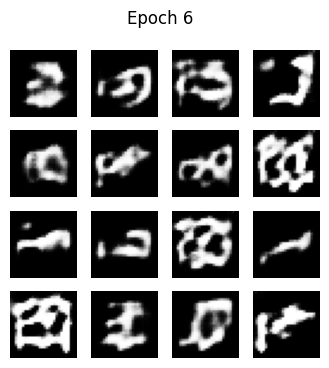

Epoch 7/10


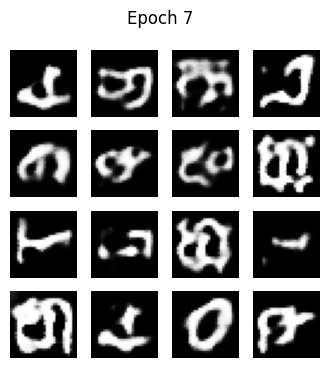

Epoch 8/10


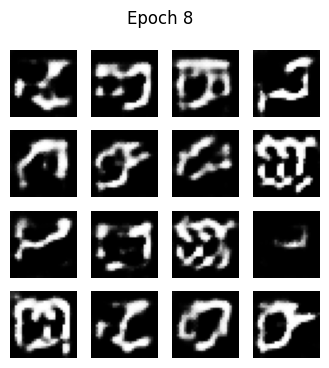

Epoch 9/10


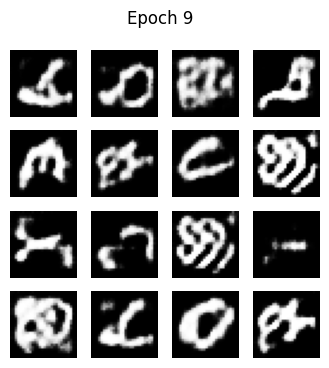

Epoch 10/10


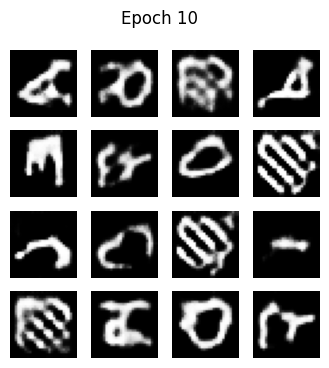

In [ ]:
# # === Generator for cGAN ===
# def make_generator_model():
#     noise_input = layers.Input(shape=(100,))
#     label_input = layers.Input(shape=(1,), dtype='int32')

#     label_embedding = layers.Embedding(num_classes, 100)(label_input)
#     label_embedding = layers.Flatten()(label_embedding)

#     model_input = layers.Multiply()([noise_input, label_embedding])

#     x = layers.Dense(7*7*256, use_bias=False)(model_input)
#     x = layers.BatchNormalization()(x)
#     x = layers.LeakyReLU()(x)

#     x = layers.Reshape((7, 7, 256))(x)

#     x = layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False)(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.LeakyReLU()(x)

#     x = layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False)(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.LeakyReLU()(x)

#     out = layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')(x)

#     return tf.keras.Model([noise_input, label_input], out)

# # === Discriminator for cGAN ===
# def make_discriminator_model():
#     img_input = layers.Input(shape=(28, 28, 1))
#     label_input = layers.Input(shape=(1,), dtype='int32')

#     label_embedding = layers.Embedding(num_classes, 28*28)(label_input)
#     label_embedding = layers.Reshape((28, 28, 1))(label_embedding)

#     x = layers.Concatenate(axis=-1)([img_input, label_embedding])

#     x = layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same')(x)
#     x = layers.LeakyReLU()(x)
#     x = layers.Dropout(0.3)(x)

#     x = layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same')(x)
#     x = layers.LeakyReLU()(x)
#     x = layers.Dropout(0.3)(x)

#     x = layers.Flatten()(x)
#     out = layers.Dense(1)(x)

#     return tf.keras.Model([img_input, label_input], out)

# # === Loss & optimizers ===
# cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# def discriminator_loss(real_output, fake_output):
#     real_loss = cross_entropy(tf.ones_like(real_output), real_output)
#     fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
#     return real_loss + fake_loss

# def generator_loss(fake_output):
#     return cross_entropy(tf.ones_like(fake_output), fake_output)

# generator = make_generator_model()
# discriminator = make_discriminator_model()

# generator_optimizer = tf.keras.optimizers.Adam(1e-4)
# discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

# # === Training Setup ===
# EPOCHS = 10
# noise_dim = 100
# num_examples_to_generate = 16

# seed_noise = tf.random.normal([num_examples_to_generate, noise_dim])
# seed_labels = tf.constant([i for i in range(num_examples_to_generate)])  # Labels 0 to 15

# @tf.function
# def train_step(images, labels):
#     noise = tf.random.normal([BATCH_SIZE, noise_dim])
#     random_labels = tf.random.uniform([BATCH_SIZE, 1], minval=0, maxval=num_classes, dtype=tf.int32)

#     with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
#         generated_images = generator([noise, random_labels], training=True)

#         real_output = discriminator([images, tf.expand_dims(labels, 1)], training=True)
#         fake_output = discriminator([generated_images, random_labels], training=True)

#         gen_loss = generator_loss(fake_output)
#         disc_loss = discriminator_loss(real_output, fake_output)

#     gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
#     gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

#     generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
#     discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

# def generate_and_show_images(model, epoch, test_noise, test_labels):
#     predictions = model([test_noise, test_labels], training=False)
#     predictions = (predictions + 1) / 2.0  # Scale to [0,1]

#     fig = plt.figure(figsize=(4,4))
#     for i in range(predictions.shape[0]):
#         plt.subplot(4,4,i+1)
#         plt.imshow(predictions[i,:,:,0], cmap='gray')
#         plt.axis('off')
#     plt.suptitle(f"Epoch {epoch}")
#     plt.show()

# def train(dataset, epochs):
#     for epoch in range(epochs):
#         print(f"Epoch {epoch+1}/{epochs}")
#         for image_batch, label_batch in dataset:
#             train_step(image_batch, label_batch)
#         generate_and_show_images(generator, epoch+1, seed_noise, seed_labels)

# # === Start training ===
# train(dataset_images_and_labels, EPOCHS)